# 03 — Modelling & Validation · Part A: Logistic Regression baseline
**NeoStats DS Hackathon — Loan Application Refusal Prediction**

**Goal of this part:** build a simple, interpretable, leakage-safe baseline that every stronger model must beat.

| Step | What we do | Hackathon requirement |
|---|---|---|
| 1 | Load the model table from notebook 01 | — |
| 2 | **Leakage guard**: scan for "answer-revealing" values and run an ablation test | Part 1 · leakage, Part 5 |
| 3 | Final modelling rows and features | Part 4 |
| 4 | Reproducible pipeline: impute + scale + one-hot, fitted on **train only** | Part 4 |
| 5 | Light tuning of the regularisation strength `C` on validation | Part 4 (stretch) |
| 6 | Class imbalance: `class_weight="balanced"` + threshold tuning | Part 4 |
| 7 | Validation KPIs: ROC-AUC, PR-AUC, precision, recall, F1, confusion matrix | Part 5 |
| 8 | Threshold choice and the precision/recall trade-off | Part 5 |
| 9 | Overfitting check, coefficients (what drives refusal) | Part 5 |
| 10 | Save model, metrics, importance | Part 4 |

**Why Logistic Regression as the baseline?**
* **Interpretable:** every coefficient says how a feature moves the odds of refusal, which credit managers and regulators can read.
* **Fast and stable** on 700k+ rows, with few hyperparameters, so it is hard to overfit.
* **Honest reference point:** if LightGBM cannot beat it clearly, the extra complexity is not worth it.
* **Limitation:** it only learns *additive, linear* effects (after our transforms). Interactions such as "cash loan × walk-in × prior refusal" are what the stronger model in Part B should add.

> **Test and OOT are not scored here.** The brief says: compare models on **validation**, choose one, then score **test once** and **OOT** at the end. Scoring test for every candidate model would turn it into a second validation set. That happens in Part C, for the chosen model only.

## 1. Setup and load

In [1]:
import os, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, accuracy_score, confusion_matrix, roc_curve, precision_recall_curve,
                             log_loss)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
SEED = 42
np.random.seed(SEED)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

# ---- Paths: same convention as notebook 01 (works on Kaggle and on your laptop) ----
ON_KAGGLE = Path("/kaggle/input").exists()
OUT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path("../outputs")
MODEL_DIR = Path("/kaggle/working") if ON_KAGGLE else Path("../models")
FIG_DIR = OUT_DIR / "figures"
for p in (MODEL_DIR, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)

TABLE = OUT_DIR / "model_table.parquet"
if not TABLE.exists():
    raise FileNotFoundError(f"{TABLE} not found - run 01_data_preparation.ipynb first.")
df = pd.read_parquet(TABLE)
groups = pd.read_csv(OUT_DIR / "feature_groups.csv")
ALL_FEATURES = groups["feature"].tolist()
print("Model table:", df.shape)
print(df.groupby("SPLIT")["REFUSED"].agg(rows="size", refusal_rate="mean").reindex(["train", "validation", "test", "oot"]).round(4))

scikit-learn 1.9.1 | pandas 3.0.5


Model table: (1327459, 60)
              rows  refusal_rate
SPLIT                           
train       714467        0.1728
validation  153100        0.1728
test        153101        0.1728
oot         306791        0.3726


In [2]:
# ---- Chart style (one consistent, colour-blind-safe look for every figure) ----
COL = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "muted": "#898781",
       "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": COL["surface"], "axes.facecolor": COL["surface"], "savefig.facecolor": COL["surface"],
    "axes.edgecolor": COL["axis"], "axes.labelcolor": COL["ink2"], "axes.titlecolor": COL["ink"],
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": COL["grid"], "grid.linewidth": 0.6, "xtick.color": COL["muted"], "ytick.color": COL["muted"],
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})
def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

## 2. Leakage guard

Notebook 01 removed the obvious post-decision columns. Two subtler problems remain, and the EDA already pointed at the first one:

1. **Incomplete records.** Some applications are missing a field that is *mandatory for their product*: a cash or consumer loan with a requested amount of **0**, a POS (consumer) loan with no **goods category** or no recorded **down payment**, or a cash/card application with no **product type** (x-sell vs walk-in). These are almost always refused because they were stopped before the form was complete. A model that sees them learns "blank mandatory field means refused", which is a data-entry artefact, not a refusal driver. It also inflates the evaluation scores, because these rows are trivially easy to predict.
2. **Lender-assigned fields.** `NAME_PORTFOLIO` (the portfolio the loan is booked into) and `NAME_YIELD_GROUP` (the interest-rate band of the offer) are set **by the lender while it decides**. They are missing almost only on refused applications. `RATE_DOWN_PAYMENT` is a normalised rate computed against the offered credit. `IS_ZERO_AMOUNT_REQUEST` is a direct flag for problem 1.

**Step 2a — scan:** on the **training split only**, and **within each contract type**, list any category level or missing-value pattern that is refused (or approved) at least 95% of the time with 300+ rows. A real driver shifts the odds; a leak *decides* them. The scan has to run within each product: across all products a blank goods category looks harmless, because it is normal for cash loans, but for POS loans it is 95% refused.

In [3]:
train_raw = df[df["SPLIT"] == "train"]
num_all = [f for f in ALL_FEATURES if pd.api.types.is_numeric_dtype(df[f])]
cat_all = [f for f in ALL_FEATURES if f not in num_all]

rows = []
for prod, grp in train_raw.groupby(train_raw["NAME_CONTRACT_TYPE"].astype(str)):
    for c in cat_all:
        if c == "NAME_CONTRACT_TYPE":
            continue
        lv = grp[c].astype("object").where(grp[c].notna(), "Missing")
        t = grp.groupby(lv)["REFUSED"].agg(["size", "mean"])
        for level, r in t.iterrows():
            if r["size"] >= 300 and (r["mean"] >= 0.95 or r["mean"] <= 0.01):
                rows.append((prod, c, level, int(r["size"]), r["mean"]))
    for c in num_all:
        m = grp[c].isna()
        if m.sum() >= 300 and grp.loc[m, "REFUSED"].mean() >= 0.95:
            rows.append((prod, c, "NaN", int(m.sum()), grp.loc[m, "REFUSED"].mean()))
    z = grp["AMT_APPLICATION"] == 0
    if prod != "Revolving loans" and z.sum():
        rows.append((prod, "AMT_APPLICATION", "= 0", int(z.sum()), grp.loc[z, "REFUSED"].mean()))
scan = pd.DataFrame(rows, columns=["contract type", "feature", "level", "train rows", "refusal rate"])
scan.sort_values(["contract type", "train rows"], ascending=[True, False]).style.format({"refusal rate": "{:.1%}", "train rows": "{:,}"})

,contract type,feature,level,train rows,refusal rate
0,Cash loans,NAME_PORTFOLIO,Missing,"4,521",100.0%
1,Cash loans,NAME_PRODUCT_TYPE,Missing,"4,521",100.0%
2,Cash loans,NAME_YIELD_GROUP,Missing,"4,521",100.0%
3,Cash loans,PRODUCT_COMBINATION,Cash,"4,521",100.0%
5,Cash loans,FINANCED_SHARE,NaN,"4,352",100.0%
6,Cash loans,AMT_APPLICATION,= 0,"4,352",100.0%
4,Cash loans,AMT_GOODS_PRICE,NaN,"3,790",100.0%
7,Consumer loans,NAME_PORTFOLIO,Missing,"7,380",100.0%
8,Consumer loans,NAME_YIELD_GROUP,Missing,"7,380",100.0%
9,Consumer loans,AMT_DOWN_PAYMENT,NaN,"1,205",98.8%


The scan confirms both problems: the lender-assigned fields (`NAME_PORTFOLIO`, `NAME_YIELD_GROUP` missing) and the blank mandatory fields (amount, goods category, product type). Several of them flag the *same* rows.

**Step 2b — ablation test.** We train the same Logistic Regression four ways and score each on the **same validation rows** (complete records only), so the comparison is apples to apples. For speed the ablation uses a 200k random sample of train; the final model uses all of train.

* **A. As prepared:** all notebook-01 features, all rows
* **B. Drop incomplete rows only**
* **C. Drop lender-assigned features only**
* **D. Drop both** (leakage-safe)

In [4]:
LENDER_ASSIGNED = ["NAME_PORTFOLIO", "NAME_YIELD_GROUP", "RATE_DOWN_PAYMENT", "IS_ZERO_AMOUNT_REQUEST"]

def is_incomplete(x):
    # An application missing a field that is mandatory for its product was stopped before it could be assessed
    ct = x["NAME_CONTRACT_TYPE"].astype(str)
    no_amount = (x["AMT_APPLICATION"] == 0) & ct.isin(["Cash loans", "Consumer loans", "XNA", "nan"])
    pos_no_goods = (ct == "Consumer loans") & x["NAME_GOODS_CATEGORY"].isna()
    pos_no_down_payment = (ct == "Consumer loans") & x["AMT_DOWN_PAYMENT"].isna()   # always recorded (even as 0) for POS
    no_product_type = ct.isin(["Cash loans", "Revolving loans"]) & x["NAME_PRODUCT_TYPE"].isna()
    return no_amount | pos_no_goods | pos_no_down_payment | no_product_type

# Long-tailed, non-negative numeric features get log1p before scaling (amounts, ratios, counts, gaps)
SKEWED = [f for f in num_all if f.startswith("AMT_") or f in
          ["APP_TO_INCOME", "INCOME_PER_FAMILY_MEMBER", "PRIOR_APP_COUNT", "PRIOR_REFUSED_COUNT",
           "DAYS_SINCE_PRIOR_APP", "CNT_CHILDREN", "CNT_FAM_MEMBERS"]]
assert (df[SKEWED].min() > -1).all(), "log1p needs values > -1"

def build_logreg(num, cat, C=1.0):
    # All steps are standard sklearn objects (no custom functions) so the saved model loads anywhere.
    skew = [f for f in num if f in SKEWED]
    plain = [f for f in num if f not in SKEWED]
    pre = ColumnTransformer([
        ("skewed", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                             ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                             ("scale", StandardScaler())]), skew),
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                              ("scale", StandardScaler())]), plain),
        ("categorical", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                                  ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                           min_frequency=0.005, sparse_output=True))]), cat),
    ])
    lr = LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED)
    return Pipeline([("preprocess", pre), ("model", lr)])

def as_object(x, cat):
    # Categorical columns -> plain object dtype (works the same on pandas 2.x and 3.x)
    x = x.copy()
    x[cat] = x[cat].astype("object").where(x[cat].notna(), np.nan)
    return x

val_raw = df[df["SPLIT"] == "validation"]
val_clean = val_raw[~is_incomplete(val_raw)]
sample = train_raw.sample(200_000, random_state=SEED)

variants = {
    "A. As prepared":                   (False, []),
    "B. Drop incomplete rows":          (True, []),
    "C. Drop lender-assigned features": (False, LENDER_ASSIGNED),
    "D. Drop both (leakage-safe)":      (True, LENDER_ASSIGNED),
}
# Extra rows: drop ONE lender-assigned feature at a time (on complete rows) to test for redundancy
for f in LENDER_ASSIGNED:
    variants[f"   D-check: drop only {f}"] = (True, [f])
abl = []
for name, (drop_rows, drop_feats) in variants.items():
    num = [f for f in num_all if f not in drop_feats]
    cat = [f for f in cat_all if f not in drop_feats]
    trn = sample[~is_incomplete(sample)] if drop_rows else sample
    m = build_logreg(num, cat).fit(as_object(trn[num + cat], cat), trn["REFUSED"])
    p = m.predict_proba(as_object(val_clean[num + cat], cat))[:, 1]
    p_all = m.predict_proba(as_object(val_raw[num + cat], cat))[:, 1]
    abl.append({"variant": name, "train rows": len(trn), "features": len(num + cat),
                "PR-AUC (val, complete rows)": average_precision_score(val_clean["REFUSED"], p),
                "ROC-AUC (val, complete rows)": roc_auc_score(val_clean["REFUSED"], p),
                "PR-AUC (val, all rows)": average_precision_score(val_raw["REFUSED"], p_all)})
abl = pd.DataFrame(abl).set_index("variant")
abl.round(4)

,train rows,features,"PR-AUC (val, complete rows)","ROC-AUC (val, complete rows)","PR-AUC (val, all rows)"
variant,,,,,
A. As prepared,200000,52,0.5914,0.8436,0.6605
B. Drop incomplete rows,196576,52,0.5913,0.8436,0.6221
C. Drop lender-assigned features,200000,48,0.5357,0.8291,0.6142
D. Drop both (leakage-safe),196576,48,0.5357,0.8296,0.5293
D-check: drop only NAME_PORTFOLIO,196576,51,0.5911,0.8436,0.6223
D-check: drop only NAME_YIELD_GROUP,196576,51,0.5907,0.8433,0.6210
D-check: drop only RATE_DOWN_PAYMENT,196576,51,0.5912,0.8435,0.6227
D-check: drop only IS_ZERO_AMOUNT_REQUEST,196576,51,0.5911,0.8436,0.6232


In [5]:
pr = abl["PR-AUC (val, complete rows)"]
print(f"Effect of removing incomplete rows from training (A -> B):     {pr['B. Drop incomplete rows'] - pr['A. As prepared']:+.3f}")
print(f"Effect of removing lender-assigned features (A -> C):          {pr['C. Drop lender-assigned features'] - pr['A. As prepared']:+.3f}")
singles = pr[pr.index.str.contains('D-check')] - pr['B. Drop incomplete rows']
print(f"Largest effect of removing any ONE lender-assigned feature:   {singles.min():+.3f}")
print(f"Headline PR-AUC on ALL validation rows: A = {abl.loc['A. As prepared', 'PR-AUC (val, all rows)']:.3f} "
      f"vs {pr['D. Drop both (leakage-safe)']:.3f} for D on complete rows")

Effect of removing incomplete rows from training (A -> B):     -0.000
Effect of removing lender-assigned features (A -> C):          -0.056
Largest effect of removing any ONE lender-assigned feature:   -0.001
Headline PR-AUC on ALL validation rows: A = 0.661 vs 0.536 for D on complete rows


**How to read the ablation** (numbers printed above):
* **Lender-assigned features are where the model leaks.** Removing them (A → C) costs a clear drop in PR-AUC on the *same* complete validation rows. The model was partly reading the lender's own pricing and booking decisions.
* **The leak is encoded redundantly.** Removing any *one* of the four features changes almost nothing, because a missing portfolio, a missing yield group, the zero-amount flag and the down-payment rate tag overlapping rows. A one-at-a-time check would wrongly conclude "no leak"; only removing the group reveals it.
* **Incomplete rows barely change the model (A → B), but they inflate evaluation.** Compare the last column: scored on *all* validation rows, every variant looks better, because the blank-field rows are trivially "refused". Keeping them in test and OOT would overstate what the model achieves on real applications.

**Decision:** use variant **D** for every model in this notebook.
* **Rows:** incomplete records (a blank mandatory field for their product) are excluded from train, validation, test and OOT. In production these go through a business rule ("complete the application before scoring") rather than the model, and the dashboard shows them as a separate *Incomplete* group.
* **Features:** `NAME_PORTFOLIO`, `NAME_YIELD_GROUP`, `RATE_DOWN_PAYMENT` and `IS_ZERO_AMOUNT_REQUEST` are removed. `NAME_YIELD_GROUP` and `NAME_PORTFOLIO` can still be used in the dashboard to *describe* the business.

We accept a lower score in exchange for a model that works on genuinely new applications. The brief rewards exactly this: *"a simple, correct and well-explained solution will score higher than a complex one with leakage."*

## 3. Final modelling rows and features

In [6]:
NUM = [f for f in num_all if f not in LENDER_ASSIGNED]
CAT = [f for f in cat_all if f not in LENDER_ASSIGNED]
FEATURES = NUM + CAT

data = df[~is_incomplete(df)].copy()
data = as_object(data, CAT)
excluded = df[is_incomplete(df)].groupby("SPLIT")["REFUSED"].agg(["size", "mean"])
inc_all = is_incomplete(df)
print(f"Incomplete records excluded: {inc_all.sum():,} (refusal rate {df.loc[inc_all, 'REFUSED'].mean():.1%})")
print(f"Share of each split that is incomplete: " + ", ".join(f"{s} {inc_all[df.SPLIT == s].mean():.1%}" for s in ["train", "validation", "test", "oot"]))

split_tbl = (data.groupby("SPLIT")["REFUSED"].agg(rows="size", refused="sum", refusal_rate="mean")
                 .reindex(["train", "validation", "test", "oot"]))
split_tbl["excluded_incomplete"] = excluded["size"].reindex(split_tbl.index).fillna(0).astype(int)
print(f"Features: {len(FEATURES)} ({len(NUM)} numeric, {len(CAT)} categorical)")
split_tbl.style.format({"rows": "{:,}", "refused": "{:,}", "refusal_rate": "{:.2%}", "excluded_incomplete": "{:,}"})

Incomplete records excluded: 40,182 (refusal rate 98.7%)
Share of each split that is incomplete: train 1.7%, validation 1.7%, test 1.7%, oot 7.4%
Features: 48 (25 numeric, 23 categorical)


,rows,refused,refusal_rate,excluded_incomplete
SPLIT,,,,
train,"702,187","111,509",15.88%,"12,280"
validation,"150,474","23,913",15.89%,"2,626"
test,"150,435","23,855",15.86%,"2,666"
oot,"284,181","91,736",32.28%,"22,610"


In [7]:
X = {s: data.loc[data["SPLIT"] == s, FEATURES] for s in ["train", "validation", "test", "oot"]}
y = {s: data.loc[data["SPLIT"] == s, "REFUSED"].to_numpy() for s in X}
ids = {s: data.loc[data["SPLIT"] == s, "SK_ID_PREV"].to_numpy() for s in X}
pos_rate = y["train"].mean()
print(f"Train refusal rate: {pos_rate:.2%}  ->  'balanced' weights: approved = {0.5/(1-pos_rate):.2f}, refused = {0.5/pos_rate:.2f}")

Train refusal rate: 15.88%  ->  'balanced' weights: approved = 0.59, refused = 3.15


## 4. The preprocessing pipeline (fitted on train only)

| Column type | Steps | Why |
|---|---|---|
| Long-tailed numeric (amounts, ratios, counts, days since last application) | median impute + missing flag → `log1p` → standardise | A linear model is distorted by a few huge values; the log compresses the tail. The missing flag lets the model learn "missing" as its own signal |
| Other numeric (ages, scores, ratings) | median impute + missing flag → standardise | Puts coefficients on a comparable scale |
| Categorical | fill `"Missing"` → one-hot; levels under 0.5% of train grouped as *infrequent* | Avoids hundreds of sparse columns; unseen levels in later data are handled safely |
| Class imbalance | `class_weight="balanced"` | Each refusal counts about 3× an approval in the loss, so the model does not ignore the minority class |

Everything sits inside one sklearn `Pipeline`. `fit` only ever sees the **training** rows, so the medians, scaling and category lists contain no validation, test or OOT information. The saved pipeline takes raw columns in and returns a probability, so the transform applied in training is exactly the one applied at scoring time.

**Why class weights and not SMOTE?** Refusals are about 1 in 6 training rows, with more than 100k examples, so the minority class is not starved. SMOTE would create synthetic applicants and roughly triple training time. Class weights reach the same goal inside the loss function, and the decision threshold is tuned separately in section 7.

## 5. Light tuning of `C` (regularisation strength)
Smaller `C` means a stronger penalty and simpler coefficients. We compare three values on validation PR-AUC, using a 200k train sample for speed. Picking `C` on **validation** is allowed; test stays untouched.

In [8]:
sub_idx = np.random.RandomState(SEED).choice(len(X["train"]), 200_000, replace=False)
tune = []
for C_ in [0.01, 0.1, 1.0]:
    t0 = time.time()
    m = build_logreg(NUM, CAT, C_).fit(X["train"].iloc[sub_idx], y["train"][sub_idx])
    p = m.predict_proba(X["validation"])[:, 1]
    tune.append({"C": C_, "val PR-AUC": average_precision_score(y["validation"], p),
                 "val ROC-AUC": roc_auc_score(y["validation"], p), "fit seconds": round(time.time() - t0, 1)})
tune = pd.DataFrame(tune).set_index("C")
BEST_C = tune["val PR-AUC"].idxmax()
print("Chosen C:", BEST_C)
tune.round(4)

Chosen C: 0.1


,val PR-AUC,val ROC-AUC,fit seconds
C,,,
0.01,0.5351,0.8296,8.3
0.10,0.5355,0.8296,10.3
1.00,0.5354,0.8296,10.9


With hundreds of thousands of rows, the regularisation strength barely matters; the data, not the penalty, determines the coefficients. We keep the best value.

## 6. Train the final Logistic Regression on the full training set

In [9]:
t0 = time.time()
logreg = build_logreg(NUM, CAT, BEST_C).fit(X["train"], y["train"])
print(f"Trained on {len(X['train']):,} rows in {time.time() - t0:.0f}s | "
      f"{logreg['model'].coef_.shape[1]} model inputs after encoding | converged in {logreg['model'].n_iter_[0]} iterations")

p_train = logreg.predict_proba(X["train"])[:, 1]
p_val = logreg.predict_proba(X["validation"])[:, 1]

Trained on 702,187 rows in 34s | 202 model inputs after encoding | converged in 143 iterations


## 7. Validation KPIs

**Why accuracy is not the main metric.** Only about 17% of validation applications are refused. A "model" that approves everyone scores about 83% accuracy and catches **zero** refusals. Accuracy rewards the majority class, so we rank models on:
* **PR-AUC (main metric):** how well the model finds refusals across all thresholds. Its baseline equals the refusal rate (about 0.17), not 0.5, so it is honest under imbalance.
* **ROC-AUC:** how well the model ranks a random refusal above a random approval. Easy to compare with other work.
* **Precision, recall, F1 and the confusion matrix** at the *chosen* threshold, which is what the business experiences day to day.

In [10]:
def kpis(y_true, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred), "accuracy": accuracy_score(y_true, pred),
            "flagged %": pred.mean(), "TP": tp, "FP": fp, "FN": fn, "TN": tn}

base = {"model": "Always 'Approved' (no model)", **kpis(y["validation"], np.zeros_like(p_val), 0.5)}
base["ROC-AUC"], base["PR-AUC"] = 0.5, y["validation"].mean()
at_05 = {"model": "Logistic Regression @ 0.50", **kpis(y["validation"], p_val, 0.5)}
pd.DataFrame([base, at_05]).set_index("model").round(4)

,ROC-AUC,PR-AUC,precision,recall,F1,accuracy,flagged %,TP,FP,FN,TN
model,,,,,,,,,,,
Always 'Approved' (no model),0.5000,0.1589,0.0000,0.0000,0.0000,0.8411,0.0000,0,0,23913,126561
Logistic Regression @ 0.50,0.8301,0.5360,0.3876,0.7174,0.5033,0.7750,0.2941,17154,27104,6759,99457


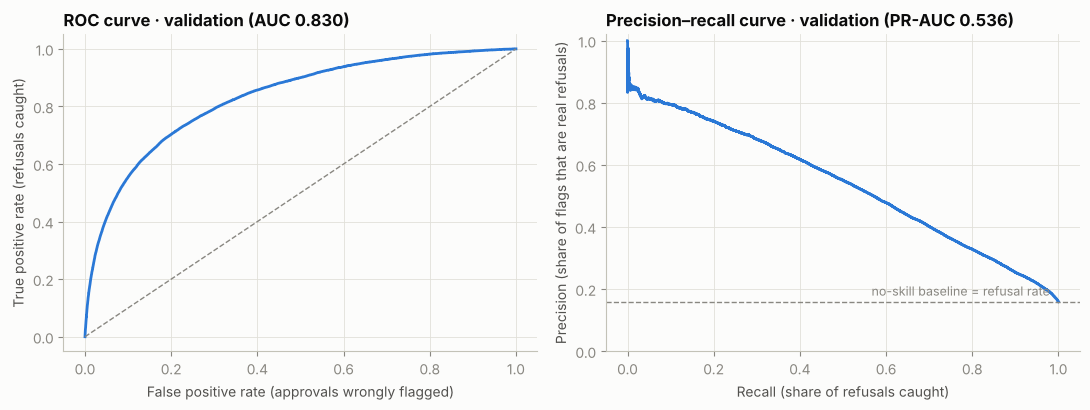

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
fpr, tpr, _ = roc_curve(y["validation"], p_val)
ax[0].plot(fpr, tpr, color=COL["blue"])
ax[0].plot([0, 1], [0, 1], color=COL["muted"], lw=1, ls="--")
ax[0].set(title=f"ROC curve · validation (AUC {roc_auc_score(y['validation'], p_val):.3f})",
          xlabel="False positive rate (approvals wrongly flagged)", ylabel="True positive rate (refusals caught)")
prec, rec, _ = precision_recall_curve(y["validation"], p_val)
ax[1].plot(rec, prec, color=COL["blue"])
ax[1].axhline(y["validation"].mean(), color=COL["muted"], lw=1, ls="--")
ax[1].text(0.98, y["validation"].mean() + 0.02, "no-skill baseline = refusal rate", ha="right", color=COL["muted"], fontsize=9)
ax[1].set(title=f"Precision–recall curve · validation (PR-AUC {average_precision_score(y['validation'], p_val):.3f})",
          xlabel="Recall (share of refusals caught)", ylabel="Precision (share of flags that are real refusals)", ylim=(0, 1.02))
fig.tight_layout(); save(fig, "lr_roc_pr_validation.png"); plt.show()

## 8. Choosing the decision threshold (on validation)

The model outputs a probability. The threshold turns it into a decision ("route to fast refusal review" vs "standard processing"):
* **Lower threshold:** catch more refusals (higher **recall**), but more good applications are flagged (lower **precision**).
* **Higher threshold:** flags are more often right, but more refusals slip through.

Because of `class_weight="balanced"`, the default 0.5 is **not** a natural cut-off. The weights push probabilities upward, so the threshold must be chosen from data. We pick the threshold that **maximises F1** on validation, a balance of precision and recall that suits a *pre-screening* use, where both wasted reviews and missed refusals cost underwriting time. If the business says a missed refusal costs more than a wasted review, choose a lower threshold from the table below.

In [12]:
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = pd.DataFrame([{"threshold": t, **{k: v for k, v in kpis(y["validation"], p_val, t).items()
                                           if k in ["precision", "recall", "F1", "flagged %"]}} for t in grid])
THRESHOLD = float(curve.loc[curve["F1"].idxmax(), "threshold"])
print(f"Chosen threshold (max F1 on validation): {THRESHOLD:.2f}")
curve[curve["threshold"].isin([0.3, 0.4, 0.5, THRESHOLD, 0.6, 0.7, 0.8])].drop_duplicates("threshold").set_index("threshold").round(3)

Chosen threshold (max F1 on validation): 0.64


,precision,recall,F1,flagged %
threshold,,,,
0.30,0.254,0.900,0.396,0.562
0.40,0.314,0.820,0.454,0.415
0.50,0.388,0.717,0.503,0.294
0.60,0.470,0.611,0.531,0.207
0.64,0.502,0.567,0.533,0.179
0.70,0.548,0.502,0.524,0.146
0.80,0.627,0.386,0.478,0.098


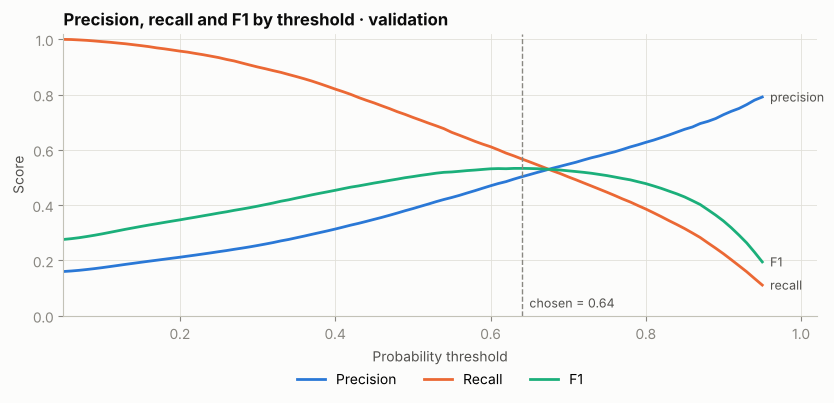

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for k, c in [("precision", COL["blue"]), ("recall", COL["orange"]), ("F1", COL["aqua"])]:
    ax.plot(curve["threshold"], curve[k], color=c, label=k.capitalize() if k != "F1" else "F1")
    ax.text(curve["threshold"].iloc[-1] + 0.01, curve[k].iloc[-1], k if k != "F1" else "F1", color=COL["ink2"], va="center", fontsize=9)
ax.axvline(THRESHOLD, color=COL["muted"], lw=1, ls="--")
ax.text(THRESHOLD + 0.01, 0.03, f"chosen = {THRESHOLD:.2f}", color=COL["ink2"], fontsize=9)
ax.set(title="Precision, recall and F1 by threshold · validation", xlabel="Probability threshold", ylabel="Score",
       ylim=(0, 1.02), xlim=(0.05, 1.02))
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.15))
fig.tight_layout(); save(fig, "lr_threshold_tradeoff.png"); plt.show()

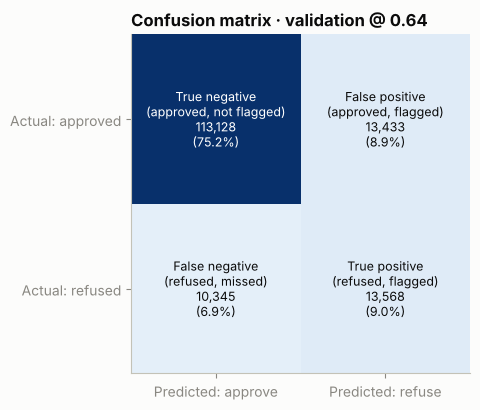

At 0.64: precision 50.2%, recall 56.7%, F1 0.533, 17.9% of applications flagged for review.


In [14]:
val_kpi = kpis(y["validation"], p_val, THRESHOLD)
cm = np.array([[val_kpi["TN"], val_kpi["FP"]], [val_kpi["FN"], val_kpi["TP"]]])
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.imshow(cm, cmap="Blues", vmin=0)
ax.grid(False)
labels = [["True negative\n(approved, not flagged)", "False positive\n(approved, flagged)"],
          ["False negative\n(refused, missed)", "True positive\n(refused, flagged)"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]:,}\n({cm[i, j] / cm.sum():.1%})", ha="center", va="center", fontsize=9,
                color="white" if cm[i, j] > cm.max() * 0.55 else COL["ink"])
ax.set_xticks([0, 1], ["Predicted: approve", "Predicted: refuse"]); ax.set_yticks([0, 1], ["Actual: approved", "Actual: refused"])
ax.set_title(f"Confusion matrix · validation @ {THRESHOLD:.2f}")
fig.tight_layout(); save(fig, "lr_confusion_validation.png"); plt.show()
print(f"At {THRESHOLD:.2f}: precision {val_kpi['precision']:.1%}, recall {val_kpi['recall']:.1%}, F1 {val_kpi['F1']:.3f}, "
      f"{val_kpi['flagged %']:.1%} of applications flagged for review.")

**Plain-English reading:** the model is shown in the printed line above. *Recall* is the share of real refusals the model flags, and *precision* is how often a flag is correct. Compare this with the "always approve" row in section 7: the baseline catches nothing.

## 9. Overfitting check and calibration note
If train scores are much higher than validation scores, the model has memorised training rows. A small gap means it generalises.

In [15]:
fit_check = pd.DataFrame({
    "train": {"ROC-AUC": roc_auc_score(y["train"], p_train), "PR-AUC": average_precision_score(y["train"], p_train)},
    "validation": {"ROC-AUC": roc_auc_score(y["validation"], p_val), "PR-AUC": average_precision_score(y["validation"], p_val)},
})
fit_check["gap (train − val)"] = fit_check["train"] - fit_check["validation"]
display(fit_check.round(4))
print(f"Mean predicted probability on validation: {p_val.mean():.3f} vs actual refusal rate {y['validation'].mean():.3f}")

,train,validation,gap (train − val)
ROC-AUC,0.8284,0.8301,-0.0017
PR-AUC,0.5301,0.5360,-0.0059


Mean predicted probability on validation: 0.390 vs actual refusal rate 0.159


* A **tiny train–validation gap** means there is no overfitting. As expected for a regularised linear model, its limit is *underfitting*: it cannot learn interactions. That is the gap Part B tests.
* **Calibration:** with balanced class weights, the average predicted probability is well above the true refusal rate. Probabilities are therefore good for **ranking**, not as literal "chance of refusal" values. This does not hurt AUC or the tuned threshold. If the final model's probabilities are shown to managers, we either calibrate them or define risk bands by rank (deciles), which is what we do in Part C.

## 10. What drives refusal? (coefficients)
Each coefficient is the change in the **log-odds** of refusal for a one-standard-deviation increase (numeric) or for belonging to that category (versus the average). `exp(coef)` is the **odds ratio**: 1.5 means 50% higher odds of refusal.

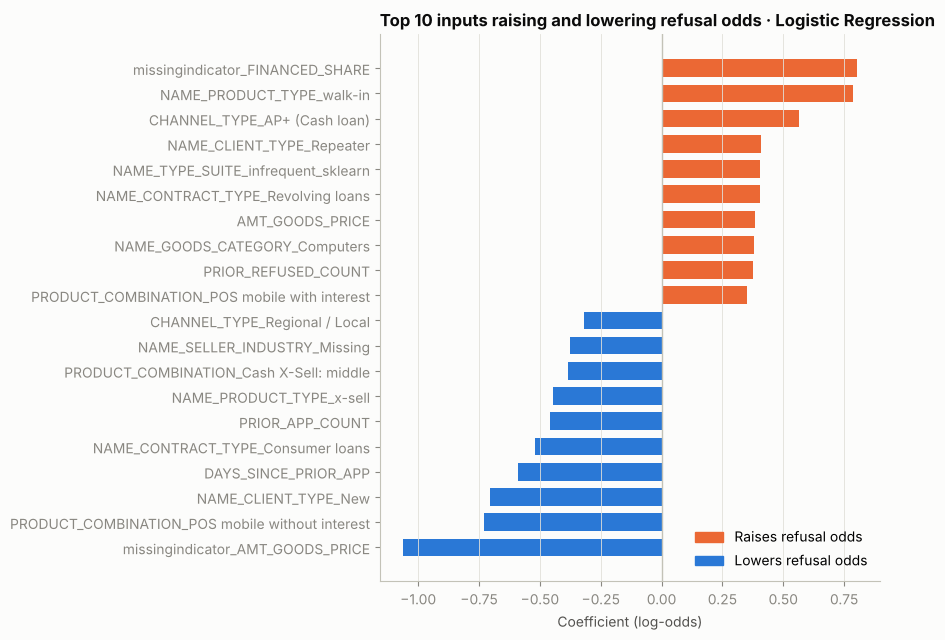

,input,group,coef,odds_ratio
33,missingindicator_FINANCED_SHARE,Product,0.804,2.234
143,NAME_PRODUCT_TYPE_walk-in,Product,0.784,2.191
173,CHANNEL_TYPE_AP+ (Cash loan),Channel,0.566,1.761
201,NAME_CLIENT_TYPE_Repeater,History,0.409,1.505
187,NAME_TYPE_SUITE_infrequent_sklearn,Channel,0.404,1.499
124,NAME_CONTRACT_TYPE_Revolving loans,Product,0.403,1.496
5,AMT_GOODS_PRICE,Product,0.385,1.470
134,NAME_GOODS_CATEGORY_Computers,Product,0.378,1.460
9,PRIOR_REFUSED_COUNT,History,0.376,1.457
157,PRODUCT_COMBINATION_POS mobile with interest,Product,0.351,1.420


In [16]:
names = logreg["preprocess"].get_feature_names_out()
coef = pd.DataFrame({"input": names, "coef": logreg["model"].coef_[0]})
coef["odds_ratio"] = np.exp(coef["coef"])
coef["input"] = coef["input"].str.replace(r"^(skewed|numeric|categorical)__", "", regex=True)

def source_feature(name):
    # Map one-hot / missing-indicator columns back to the original feature
    if name.startswith("missingindicator_"):
        return name.replace("missingindicator_", "")
    for f in sorted(FEATURES, key=len, reverse=True):
        if name == f or name.startswith(f + "_"):
            return f
    return name
coef["feature"] = coef["input"].map(source_feature)
coef["group"] = coef["feature"].map(groups.set_index("feature")["group"]).fillna("Other")

top = pd.concat([coef.nlargest(10, "coef"), coef.nsmallest(10, "coef")]).sort_values("coef")
fig, ax = plt.subplots(figsize=(9, 6.5))
colors = np.where(top["coef"] > 0, COL["orange"], COL["blue"])
ax.barh(top["input"], top["coef"], color=colors, height=0.7)
ax.axvline(0, color=COL["axis"], lw=1)
ax.set(title="Top 10 inputs raising and lowering refusal odds · Logistic Regression", xlabel="Coefficient (log-odds)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COL["orange"], label="Raises refusal odds"), Patch(color=COL["blue"], label="Lowers refusal odds")],
          loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "lr_top_coefficients.png"); plt.show()
top.sort_values("coef", ascending=False)[["input", "group", "coef", "odds_ratio"]].round(3)

In [17]:
# Global importance per ORIGINAL feature = sum of |coefficients| of its encoded columns (inputs are standardised)
importance = (coef.groupby(["feature", "group"])["coef"].apply(lambda s: s.abs().sum())
                 .rename("importance").reset_index().sort_values("importance", ascending=False))
importance["importance_share"] = importance["importance"] / importance["importance"].sum()
importance.insert(0, "model", "Logistic Regression")
print("Importance by feature group:")
print(importance.groupby("group")["importance_share"].sum().sort_values(ascending=False).round(3).to_string())
importance.head(15).round(4)

Importance by feature group:
group
Product        0.510
History        0.148
Financial      0.139
Channel        0.131
Demographic    0.072


,model,feature,group,importance,importance_share
44,Logistic Regression,PRODUCT_COMBINATION,Product,3.0547,0.1299
7,Logistic Regression,CHANNEL_TYPE,Channel,1.6248,0.0691
36,Logistic Regression,NAME_PRODUCT_TYPE,Product,1.5342,0.0652
4,Logistic Regression,AMT_GOODS_PRICE,Product,1.4493,0.0616
28,Logistic Regression,NAME_CLIENT_TYPE,History,1.4434,0.0614
40,Logistic Regression,ORGANIZATION_TYPE,Financial,1.4343,0.0610
37,Logistic Regression,NAME_SELLER_INDUSTRY,Product,1.3928,0.0592
38,Logistic Regression,NAME_TYPE_SUITE,Channel,1.2920,0.0549
32,Logistic Regression,NAME_GOODS_CATEGORY,Product,1.2878,0.0547
29,Logistic Regression,NAME_CONTRACT_TYPE,Product,1.2050,0.0512


**Caveat when presenting coefficients:** features that move together (for example the three `EXT_SOURCE` scores and their mean, or prior-refusal count and rate) share their effect, so an individual coefficient can look smaller, or even flip sign, compared with its EDA effect. Read *groups* of related features together, and use the stronger model's importance (Part B) as a cross-check.

## 11. Save the model and results

In [18]:
joblib.dump(logreg, MODEL_DIR / "logreg_pipeline.joblib")

metrics_row = {"model": "Logistic Regression", "split": "validation", "threshold": THRESHOLD, "C": BEST_C,
               **{k: (round(float(v), 4) if isinstance(v, float) else int(v)) for k, v in val_kpi.items()}}
pd.DataFrame([metrics_row]).to_csv(OUT_DIR / "model_metrics_validation_logreg.csv", index=False)
importance.to_csv(OUT_DIR / "feature_importance_logreg.csv", index=False)
pd.DataFrame({"SK_ID_PREV": ids["validation"], "REFUSED": y["validation"], "proba_logreg": p_val}) \
  .to_parquet(OUT_DIR / "val_predictions_logreg.parquet", index=False)
json.dump({"model": "Logistic Regression", "threshold": THRESHOLD, "C": float(BEST_C), "features": FEATURES,
           "numeric": NUM, "categorical": CAT, "excluded_features": LENDER_ASSIGNED,
           "row_rule": "exclude incomplete records: AMT_APPLICATION == 0 (cash/consumer), consumer loan without NAME_GOODS_CATEGORY or AMT_DOWN_PAYMENT, cash/revolving without NAME_PRODUCT_TYPE"},
          open(MODEL_DIR / "logreg_config.json", "w"), indent=2)

# Reload check: the saved pipeline must reproduce the same scores
reloaded = joblib.load(MODEL_DIR / "logreg_pipeline.joblib")
assert np.allclose(reloaded.predict_proba(X["validation"].head(1000))[:, 1], p_val[:1000])
for f in ["logreg_pipeline.joblib", "logreg_config.json"]:
    print(f"  models/{f:32s} {(MODEL_DIR / f).stat().st_size / 1e3:8.1f} KB")
for f in ["model_metrics_validation_logreg.csv", "feature_importance_logreg.csv", "val_predictions_logreg.parquet"]:
    print(f"  outputs/{f:32s} {(OUT_DIR / f).stat().st_size / 1e3:8.1f} KB")

  models/logreg_pipeline.joblib               22.9 KB
  models/logreg_config.json                    2.8 KB
  outputs/model_metrics_validation_logreg.csv      0.2 KB
  outputs/feature_importance_logreg.csv         4.3 KB
  outputs/val_predictions_logreg.parquet     2518.3 KB


## Summary: what to say about this baseline
* **Leakage guard:** a within-product scan and an ablation showed that lender-assigned fields (portfolio, yield group, down-payment rate, zero-amount flag) inflate the score. The leak is redundant, so removing one feature alone hides it. Incomplete records (blank mandatory fields) were excluded because they inflate evaluation. We accepted a lower but honest score.
* **Model:** Logistic Regression in a single sklearn pipeline (median impute + missing flags, `log1p` for long tails, standardise, one-hot), fitted on train only, fixed seed.
* **Imbalance:** `class_weight="balanced"` plus a threshold chosen on validation (max F1). No SMOTE: the minority class is large, and resampling would distort probabilities.
* **Results:** validation ROC-AUC and PR-AUC as printed above; small train–validation gap, so no overfitting.
* **Drivers:** see the coefficient chart. History, external scores and product/channel dominate, matching the EDA.

**Next — Part B:** LightGBM on the same rows, features and splits, with `scale_pos_weight`, compared with this baseline in one validation KPI table. **Part C:** choose the final model and threshold, then score **test once** and **OOT**, add risk bands, and export `predictions.csv`, `feature_importance.csv` and `model_metrics.csv` for the dashboard.